# 01. Разведка проблем в данных

Шаг 2.2a — перед очисткой. Контекст: `решения.md`, раздел 1.3.
**Только считаем и смотрим** — данные в `data/processed/` не меняются, пороги и правила очистки не применяются.

По каждому пункту: сколько книг / оценок затронуто (число и %), примеры. В конце — сводная таблица.

In [1]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]  # ноутбук лежит в ml/notebooks/
PROCESSED = ROOT / "data" / "processed"

pd.options.display.max_colwidth = 110
pd.options.display.width = 200
pd.options.display.max_rows = 60

# Графики: один цвет, тонкие столбцы, светлая сетка
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d9d8d3",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

meta = pd.read_parquet(PROCESSED / "books_meta.parquet")
ratings = pd.read_parquet(PROCESSED / "ratings_5core.parquet")
N_BOOKS, N_RATINGS = len(meta), len(ratings)
ratings_per_book = ratings["parent_asin"].value_counts()
meta["n_ratings_5core"] = meta["parent_asin"].map(ratings_per_book).astype("int32")

# details — JSON-строка; разбираем один раз
details = meta["details"].map(json.loads)

# subtitle в Amazon — не подзаголовок, а «формат – дата»: "Paperback – October 26, 2010"
meta["format"] = meta["subtitle"].fillna("").str.split(" – ").str[0].str.strip()

cats = meta["categories"].map(list)
meta["root"] = cats.map(lambda c: c[0] if len(c) > 0 else None)
meta["cat2"] = cats.map(lambda c: c[1] if len(c) > 1 else None)
meta["cat3"] = cats.map(lambda c: c[2] if len(c) > 2 else None)

summary = []  # (проблема, затронуто, предложение) — заполняется по ходу

def pct(n, total):
    return f"{n:,} ({n / total:.1%})"

def ratings_of(mask):
    """Сколько оценок 5-core приходится на книги из маски."""
    return int(meta.loc[mask, "n_ratings_5core"].sum())

print(f"Книг: {N_BOOKS:,}, оценок: {N_RATINGS:,}, пользователей: {ratings['user_id'].nunique():,}")

Книг: 495,063, оценок: 9,488,297, пользователей: 776,370


## 1. Дубли изданий

Одна книга в разных изданиях (мягкая / твёрдая обложка, Kindle, аудио) получает разные `parent_asin`.
Ключ дубля — нормализованные **название + автор**:
- **строгий ключ** — название без скобок `(...)` и без пометок изданий («2nd Edition», «Deluxe Edition», «Revised»…), регистр и пунктуация не учитываются;
- **мягкий ключ** — то же, но только часть названия до двоеточия (чтобы поймать разные подзаголовки).

Книги без автора в поиск дублей не попадают (их считаем отдельно).

In [2]:
EDITION_RE = re.compile(
    r"\b(\d+(st|nd|rd|th)\s+)?(\d+(st|nd|rd|th)|first|second|third|fourth|fifth|revised|updated|expanded|anniversary|"
    r"deluxe|collector'?s|special|illustrated|annotated|unabridged|abridged|large print|"
    r"new|international|student|library|mass market|reprint|definitive|complete)\s+(edition|ed\.)",
    re.I,
)
PARENS_RE = re.compile(r"\([^)]*\)|\[[^\]]*\]")

def norm_text(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"&", " and ", s)
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def title_key(t):
    return norm_text(EDITION_RE.sub(" ", PARENS_RE.sub(" ", t)))

def title_key_loose(t):
    return title_key(PARENS_RE.sub(" ", t).split(":")[0])

has_author = meta["author"].notna()
meta["author_key"] = meta["author"].fillna("").map(norm_text)
meta["key_strict"] = meta["author_key"] + " | " + meta["title"].fillna("").map(title_key)
meta["key_loose"] = meta["author_key"] + " | " + meta["title"].fillna("").map(title_key_loose)

def dup_stats(key):
    k = meta.loc[has_author, key]
    sizes = k.map(k.value_counts())
    in_dup = sizes[sizes > 1].index
    n_groups = k.loc[in_dup].nunique()
    extra = len(in_dup) - n_groups  # «лишние» карточки, которые исчезнут при склейке
    return in_dup, n_groups, extra

dup_idx, n_groups, extra = dup_stats("key_strict")
loose_idx, n_groups_l, extra_l = dup_stats("key_loose")
dup_mask = meta.index.isin(dup_idx)

print(f"Книг без автора (не проверялись): {pct((~has_author).sum(), N_BOOKS)}")
print()
print("Строгий ключ (название без скобок и пометок изданий + автор):")
print(f"  групп-дублей:           {n_groups:,}")
print(f"  книг в этих группах:    {pct(len(dup_idx), N_BOOKS)}")
print(f"  «лишних» карточек:      {pct(extra, N_BOOKS)}")
print(f"  оценок на этих книгах:  {pct(ratings_of(dup_mask), N_RATINGS)}")
print()
print("Мягкий ключ (только часть до двоеточия + автор):")
print(f"  групп-дублей:           {n_groups_l:,}")
print(f"  книг в этих группах:    {pct(len(loose_idx), N_BOOKS)}")
print(f"  «лишних» карточек:      {pct(extra_l, N_BOOKS)}")

Книг без автора (не проверялись): 59,614 (12.0%)

Строгий ключ (название без скобок и пометок изданий + автор):
  групп-дублей:           45,650
  книг в этих группах:    104,594 (21.1%)
  «лишних» карточек:      58,944 (11.9%)
  оценок на этих книгах:  3,566,447 (37.6%)

Мягкий ключ (только часть до двоеточия + автор):
  групп-дублей:           54,568
  книг в этих группах:    132,979 (26.9%)
  «лишних» карточек:      78,411 (15.8%)


In [3]:
# Размер групп и сочетания форматов внутри групп — подтверждают, что это издания одной книги
groups = meta.loc[dup_mask].groupby("key_strict")
print("Размер групп:")
print(groups.size().value_counts().sort_index().head(8).to_string())
print()
print("Частые сочетания форматов в группах:")
combos = groups["format"].agg(lambda f: " + ".join(sorted(x or "?" for x in f)))
print(combos.value_counts().head(10).to_string())

Размер групп:


2    36726
3     6574
4     1434
5      464
6      194
7      118
8       55
9       26

Частые сочетания форматов в группах:


format
Hardcover + Paperback                     12637
Kindle Edition + Paperback                 4923
Paperback + Paperback                      2799
Hardcover + Kindle Edition                 2630
Hardcover + Mass Market Paperback          2246
? + Paperback                              2178
? + Hardcover                              1878
Hardcover + Kindle Edition + Paperback     1407
Kindle Edition + Mass Market Paperback     1174
Hardcover + Hardcover                       903


In [4]:
# 10 примеров: самые оценённые группы
cols = ["key_strict", "parent_asin", "title", "author", "format", "n_ratings_5core"]
top_keys = (meta.loc[dup_mask].groupby("key_strict")["n_ratings_5core"].sum()
            .sort_values(ascending=False).index[:10])
meta.loc[meta["key_strict"].isin(top_keys), cols].sort_values(["key_strict", "n_ratings_5core"], ascending=[True, False])

,key_strict,parent_asin,title,author,format,n_ratings_5core
434812,a g riddle | the atlantis gene a thriller,B00C2WDD5I,"The Atlantis Gene: A Thriller (The Origin Mystery, Book 1)",A.G. Riddle,,3671
373517,a g riddle | the atlantis gene a thriller,1940026016,"The Atlantis Gene: A Thriller (The Origin Mystery, Book 1)",A.G. Riddle,,279
330384,a g riddle | the atlantis gene a thriller,1940026040,"The Atlantis Gene: A Thriller (the Origin Mystery, Book 1)",A.G. Riddle,Hardcover,11
56095,amor towles | a gentleman in moscow a novel,B01COJUEZ0,A Gentleman in Moscow: A Novel,Amor Towles,Kindle Edition,3404
48122,amor towles | a gentleman in moscow a novel,0670026190,A Gentleman in Moscow: A Novel,Amor Towles,Hardcover,994
423257,amor towles | a gentleman in moscow a novel,0143110438,A Gentleman in Moscow: A Novel,Amor Towles,Paperback,402
59955,amor towles | a gentleman in moscow a novel,1524708690,A Gentleman in Moscow: A Novel,Amor Towles,Paperback,86
118552,amor towles | a gentleman in moscow a novel,0735288526,A Gentleman in Moscow: A Novel,Amor Towles,Audio CD,22
386083,anthony doerr | all the light we cannot see a novel,B00DPM7TIG,All the Light We Cannot See: A Novel,Anthony Doerr,,7127
164942,anthony doerr | all the light we cannot see a novel,1442375426,All the Light We Cannot See: A Novel,Anthony Doerr,Audio CD,51


In [5]:
# Пользователи, оценившие несколько изданий одной книги (п. 6 в 1.3: «оставляем последнюю оценку»)
r = ratings.merge(meta.loc[dup_mask, ["parent_asin", "key_strict"]], on="parent_asin")
multi = r.groupby(["user_id", "key_strict"]).size()
print(f"Пар (пользователь, книга), где оценено 2+ издания: {(multi > 1).sum():,}")
print(f"Оценок в таких парах: {multi[multi > 1].sum():,} ({multi[multi > 1].sum() / N_RATINGS:.2%} всех)")

Пар (пользователь, книга), где оценено 2+ издания: 3,729
Оценок в таких парах: 7,938 (0.08% всех)


### 1a. Пограничные случаи

- **Серии и тома** — в группе есть названия с разными номерами («Book 1» / «Book 2», «Vol. 2», «Part 3»): склейка была бы **ошибкой**.
- **Особые издания** — «Deluxe / Collector's / Anniversary Edition»: это та же книга, склеивать можно.
- **Разные подзаголовки** — совпадает часть до двоеточия, а после — разное: бывает и та же книга, и разные.

In [6]:
VOL_RE = re.compile(r"\b(book|vol\.?|volume|part|no\.?|#|tome|bk\.?)\s*(\d+)", re.I)

def volumes(t):
    return frozenset(n for _, n in VOL_RE.findall(t or ""))

meta["volumes"] = meta["title"].map(volumes)
groups = meta.loc[dup_mask].groupby("key_strict")
vol_conflict = groups["volumes"].agg(lambda v: len({x for x in v if x}) > 1)
vol_keys = vol_conflict[vol_conflict].index
print(f"Групп с разными номерами томов: {len(vol_keys):,} "
      f"(книг: {meta['key_strict'].isin(vol_keys).sum():,}) — склеивать нельзя")
meta.loc[meta["key_strict"].isin(vol_keys[:8]), ["key_strict", "title", "author", "format"]].sort_values("key_strict")

Групп с разными номерами томов: 59 (книг: 157) — склеивать нельзя


,key_strict,title,author,format
472743,aleksandr solzhenitsyn | the gulag archipelago an experiment in literary investigation,The Gulag Archipelago [Volume 3]: An Experiment in Literary Investigation,Aleksandr Solzhenitsyn,Paperback
181459,aleksandr solzhenitsyn | the gulag archipelago an experiment in literary investigation,The Gulag Archipelago [Volume 2]: An Experiment in Literary Investigation,Aleksandr Solzhenitsyn,Paperback
309070,alexander mccall smith | in the company of cheerful ladies,"In the Company of Cheerful Ladies (No. 1 Ladies' Detective Agency, Book 6)",Alexander McCall Smith,Hardcover
193062,alexander mccall smith | in the company of cheerful ladies,In the Company of Cheerful Ladies (No. 1 Ladies' Detective Agency),Alexander McCall Smith,Audio CD
343616,alexander mccall smith | the limpopo academy of private detection,The Limpopo Academy of Private Detection (No. 1 Ladies' Detective Agency Series),Alexander McCall Smith,Paperback
306466,alexander mccall smith | the limpopo academy of private detection,The Limpopo Academy of Private Detection (No. 1 Ladies' Detective Agency Series),Alexander McCall Smith,Hardcover
280000,alexander mccall smith | the limpopo academy of private detection,"The Limpopo Academy of Private Detection (No. 1 Ladies' Detective Agency Series, No. 13)",Alexander McCall Smith,Audio CD
33651,amanda charles | loving angelica italian lovers,Loving Angelica: Italian Lovers (Book 5),Amanda Charles,Kindle Edition
486796,amanda charles | loving angelica italian lovers,Loving Angelica: Italian Lovers (Book 3),Amanda Charles,Kindle Edition
144714,amanda charles | loving angelica italian lovers,Loving Angelica: Italian Lovers (Book 1),Amanda Charles,Kindle Edition


In [7]:
# Тома в названиях в целом (вне групп-дублей) — масштаб «серийности»
any_vol = meta["volumes"].map(len) > 0
print(f"Книг с номером тома/книги в названии: {pct(any_vol.sum(), N_BOOKS)}")
meta.loc[any_vol, ["title", "author"]].sample(8, random_state=1)

Книг с номером тома/книги в названии: 47,255 (9.5%)


,title,author
351806,Lillie (Maggie Trilogy Series Book 3),Mya O'Malley
476454,The Professor (McMurtrie and Drake Legal Thrillers Book 1),Robert Bailey
202029,Falling Star (Joe Costa Series Book 6),Henry Simpson
119844,The First Christmas After the War (An American Family's Wartime Saga Book 3),Alan R. Simon
202512,The House on Judith Street: Inspired by True Events (The NightStalkers Series Book 1),Monte Plaisance
135123,Mists of the Past (A Darcy Sweet Cozy Mystery Book 2),K.J. Emrick
120259,"Grave Surprise (Harper Connelly Mysteries, Book 2)",Charlaine Harris
298989,Sixth Covenant (A.D. Chronicles Book 6),Brock Thoene


In [8]:
special = meta["title"].fillna("").str.contains(
    r"\b(?:deluxe|collector'?s|anniversary|special|definitive|gift)\s+edition", case=False, regex=True)
special_in_dup = special & dup_mask
print(f"Книг с «особым изданием» в названии: {special.sum():,}; из них попали в группы-дубли: {special_in_dup.sum():,}")
keys = meta.loc[special_in_dup, "key_strict"].unique()[:6]
meta.loc[meta["key_strict"].isin(keys), ["key_strict", "title", "format", "n_ratings_5core"]].sort_values("key_strict")

Книг с «особым изданием» в названии: 1,426; из них попали в группы-дубли: 471


,key_strict,title,format,n_ratings_5core
1308,dan abnett | horus rising,Horus Rising: Anniversary Edition (1) (Horus Heresy),Paperback,8
254192,dan abnett | horus rising,Horus Rising (The Horus Heresy),Paperback,25
419159,dan abnett | horus rising,Horus Rising (1) (The Horus Heresy),,14
2945,gustave flaubert | madame bovary,Madame Bovary: (Penguin Classics Deluxe Edition),Kindle Edition,18
429604,gustave flaubert | madame bovary,Madame Bovary,Paperback,6
16202,gustave flaubert | madame bovary,Madame Bovary (Oxford World's Classics),Paperback,8
409759,gustave flaubert | madame bovary,Madame Bovary (Dover Thrift Editions: Classic Novels),Paperback,7
371279,gustave flaubert | madame bovary,Madame Bovary: (Penguin Classics Deluxe Edition),Paperback,13
314783,gustave flaubert | madame bovary,Madame Bovary (Penguin Classics),Paperback,42
147913,gustave flaubert | madame bovary,Madame Bovary,Mass Market Paperback,7


In [9]:
# Разные подзаголовки: одинаковый мягкий ключ, но разные строгие
loose_groups = meta.loc[meta.index.isin(loose_idx)].groupby("key_loose")["key_strict"].nunique()
diff_sub = loose_groups[loose_groups > 1].index
print(f"Групп «то же до двоеточия, другое после»: {len(diff_sub):,} "
      f"(книг: {meta['key_loose'].isin(diff_sub).sum():,})")
ex = pd.Series(diff_sub).sample(8, random_state=3)
meta.loc[meta["key_loose"].isin(ex), ["key_loose", "title", "format", "n_ratings_5core"]].sort_values("key_loose")

Групп «то же до двоеточия, другое после»: 15,137 (книг: 44,054)


,key_loose,title,format,n_ratings_5core
44564,a m lindbergh | gift from the sea,Gift from the sea,Hardcover,6
109967,a m lindbergh | gift from the sea,Gift from the Sea: 50th-Anniversary Edition,Paperback,108
91652,claire fontaine | come back,Come Back: A Mother and Daughter's Journey Through Hell and Back (P.S.),Paperback,6
344559,claire fontaine | come back,Come Back: A Mother and Daughter's Journey Through Hell and Back (P.S.),Paperback,8
208604,claire fontaine | come back,Come Back,Paperback,9
78217,holly wagner | warrior chicks,Warrior Chicks: Rising Strong When Life Wants to Take You Down,Paperback,18
102019,holly wagner | warrior chicks,"Warrior Chicks: Rising Strong, Beautiful & Confident",Paperback,6
130332,j w rinzler | star wars storyboards,Star Wars Storyboards: The Prequel Trilogy,Hardcover,21
267783,j w rinzler | star wars storyboards,Star Wars Storyboards: The Original Trilogy,Hardcover,50
160895,james h gilmore | the experience economy,"The Experience Economy, Updated Edition",Paperback,11


## 2. Не книги

Правила-кандидаты: слова в названии, категории и формат издания (`subtitle` = «Calendar – …», «Cards – …»).
Для каждого правила — сколько ловит, в каких разделах, и **самые популярные срабатывания**: если правило ловит
известный роман, это ложное срабатывание (у настоящих «не книг» обычно мало оценок).

In [10]:
title = meta["title"].fillna("")
cat_str = cats.map(" > ".join)

RULES = {
    "название: calendar":            title.str.contains(r"\bcalendars?\b", case=False),
    "название: calendar + год/wall/desk": title.str.contains(r"\bcalendars?\b", case=False)
        & title.str.contains(r"\b(?:19|20)\d\d\b|wall|page-a-day|day-to-day|engagement|desk", case=False),
    "название: notebook / journal":  title.str.contains(r"\b(?:notebook|journal|composition book|sketchbook|logbook|log book)\b", case=False),
    "название: planner / organizer": title.str.contains(r"\b(?:planner|organizer|agenda)\b", case=False),
    "название: diary":               title.str.contains(r"\bdiary\b", case=False),
    "название: coloring book":       title.str.contains(r"\bcolou?ring\b", case=False),
    "название: summary of":          title.str.contains(r"^\s*summary\b|\bsummary\s*(?:of|and analysis|&)\b", case=False),
    "название: workbook for":        title.str.contains(r"\bworkbook\s+(?:for|on|to)\b", case=False),
    "название: study guide":         title.str.contains(r"\bstudy guide\b", case=False),
    "категория: Calendars":          cat_str.str.contains(r"\bCalendars\b"),
    "категория: Stationery":         cat_str.str.contains("Stationery, Journals & Notebooks"),
    "категория: Audible":            meta["root"].eq("Audible Books & Originals"),
    "формат: Calendar/Cards/Map/Diary": meta["format"].isin(["Calendar", "Cards", "Map", "Diary", "Wall Chart", "Poster"]),
}

FICTION = {"Literature & Fiction", "Mystery, Thriller & Suspense", "Romance", "Science Fiction & Fantasy",
           "Teen & Young Adult", "Children's Books", "Comics & Graphic Novels"}

rows = []
for name, mask in RULES.items():
    rows.append({
        "правило": name,
        "книг": mask.sum(),
        "% книг": f"{mask.mean():.2%}",
        "оценок": ratings_of(mask),
        "из них в худож. разделах": (mask & meta["cat2"].isin(FICTION)).sum(),
        "топ-3 раздела": ", ".join(f"{c} ({n})" for c, n in meta.loc[mask, "cat2"].value_counts().head(3).items()),
    })
rules_df = pd.DataFrame(rows)
any_rule = np.logical_or.reduce(list(RULES.values()))
print(f"Хотя бы одно правило: {pct(any_rule.sum(), N_BOOKS)} книг, {pct(ratings_of(any_rule), N_RATINGS)} оценок")
rules_df

Хотя бы одно правило: 15,283 (3.1%) книг, 271,569 (2.9%) оценок


,правило,книг,% книг,оценок,из них в худож. разделах,топ-3 раздела
0,название: calendar,2840,0.57%,33748,260,"Arts & Photography (742), Humor & Entertainment (493), Calendars (428)"
1,название: calendar + год/wall/desk,2722,0.55%,32133,210,"Arts & Photography (739), Humor & Entertainment (488), Calendars (420)"
2,название: notebook / journal,1911,0.39%,32186,429,"Stationery, Journals & Notebooks (306), Children's Books (270), Arts & Photography (178)"
3,название: planner / organizer,632,0.13%,10180,109,"Arts & Photography (81), Crafts, Hobbies & Home (78), Mystery, Thriller & Suspense (39)"
4,название: diary,1018,0.21%,22889,514,"Children's Books (249), Literature & Fiction (176), Biographies & Memoirs (124)"
5,название: coloring book,5592,1.13%,121783,1466,"Crafts, Hobbies & Home (2289), Children's Books (1408), Arts & Photography (1390)"
6,название: summary of,22,0.00%,163,4,"Christian Books & Bibles (4), Education & Teaching (3), Reference (2)"
7,название: workbook for,421,0.09%,6888,154,"Children's Books (138), Education & Teaching (57), Reference (44)"
8,название: study guide,822,0.17%,9025,26,"New, Used & Rental Textbooks (209), Christian Books & Bibles (126), Test Preparation (89)"
9,категория: Calendars,473,0.10%,4276,0,Calendars (473)


In [11]:
# Самые популярные срабатывания каждого правила — здесь видны ложные
show = ["title", "author", "format", "cat2", "n_ratings_5core"]
for name, mask in RULES.items():
    print(f"\n=== {name} — {mask.sum():,} книг; 5 самых оценённых:")
    print(meta.loc[mask, show].nlargest(5, "n_ratings_5core").to_string(index=False, max_colwidth=70))


=== название: calendar — 2,840 книг; 5 самых оценённых:
                                                                 title                 author    format                   cat2  n_ratings_5core
Katie Daisy 2019 On-the-Go Weekly Planner: 17-Month Calendar with P... Amber Lotus Publishing  Calendar  Humor & Entertainment              215
The Knot Ultimate Wedding Planner & Organizer [binder edition]: Wor...           Carley Roney Hardcover Crafts, Hobbies & Home              175
                                     365 Cats Page-A-Day Calendar 2017                   None  Calendar     Arts & Photography               99
Katie Daisy 2020 On-the-Go Weekly Planner: 17-Month Calendar with P... Amber Lotus Publishing               Arts & Photography               99
                                            Mom's Family Calendar 2015         Sandra Boynton  Calendar  Humor & Entertainment               88

=== название: calendar + год/wall/desk — 2,722 книг; 5 самых оценённых:
      


=== название: coloring book — 5,592 книг; 5 самых оценённых:


                                                                 title          author    format               cat2  n_ratings_5core
     Secret Garden: An Inky Treasure Hunt and Coloring Book for Adults Johanna Basford Paperback Arts & Photography             1644
           Creative Haven Creative Cats Coloring Book (Adult Coloring) Marjorie Sarnat Paperback Arts & Photography             1345
Enchanted Forest: An Inky Quest and Coloring book (Activity Books, ... Johanna Basford Paperback   Children's Books             1315
Dover Creative Haven Art Nouveau Animal Designs Coloring Book (Crea...     Marty Noble Paperback Arts & Photography              900
     Creative Haven Owls Coloring Book (Adult Coloring Books: Animals) Marjorie Sarnat Paperback Arts & Photography              825

=== название: summary of — 22 книг; 5 самых оценённых:
                                                                 title                   author    format                         cat2  n_ratings


=== категория: Stationery — 600 книг; 5 самых оценённых:
                                                                 title               author           format                             cat2  n_ratings_5core
One Line A Day: A Five-Year Memory Book (5 Year Journal, Daily Jour...      Chronicle Books                  Stationery, Journals & Notebooks              329
                              Q&A a Day for Kids: A Three-Year Journal         Betsy Franco        Hardcover Stationery, Journals & Notebooks              231
                                   Celestial Journal (Diary, Notebook)                 None            Diary Stationery, Journals & Notebooks              198
                                Your Birthday Book: A Keepsake Journal Amy Krouse Rosenthal Hardcover-spiral Stationery, Journals & Notebooks              187
Celestial Large-Format Internet Address & Password Logbook (removab...                 None Hardcover-spiral Stationery, Journals & Notebooks      

In [12]:
# Случайные срабатывания — как выглядит «типичный» улов
for name, mask in RULES.items():
    if mask.sum() == 0:
        continue
    print(f"\n=== {name}: 5 случайных")
    print(meta.loc[mask, show].sample(min(5, mask.sum()), random_state=0).to_string(index=False, max_colwidth=70))


=== название: calendar: 5 случайных
                                       title              author   format                   cat2  n_ratings_5core
              Handbags 2013 Gallery Calendar Workman Publishing. Calendar     Arts & Photography                6
Quilting Block & Pattern-a-Day 2018 Calendar      Debby Kratovil Calendar Crafts, Hobbies & Home               13
                  Chihuly 2019 Wall Calendar        Dale Chihuly Calendar     Arts & Photography                5
    Paint by Sticker Cats Wall Calendar 2020                None Calendar Crafts, Hobbies & Home                7
   Sports Jeopardy! 2020 Day-to-Day Calendar                None Calendar  Humor & Entertainment                5

=== название: calendar + год/wall/desk: 5 случайных
                                                                 title              author   format                         cat2  n_ratings_5core
   Thomas Kinkade Studios: Disney Dreams Collection 2020 Wall Calendar      Thom

                                                                 title             author    format                             cat2  n_ratings_5core
Journal to the Self: Twenty-Two Paths to Personal Growth - Open the...     Kathleen Adams                                  Self-Help                7
The Best Used Boat Notebook: From the Pages of Sailing Mazine, a Ne...               None Paperback     Engineering & Transportation                5
                 Large Sketchbook (Black) (Watson Guptill Sketchbooks)               None Hardcover               Arts & Photography               58
Trips Journal (Notebook, Diary) (Travel Journal) (Small Format Jour... Peter Pauper Press     Diary Stationery, Journals & Notebooks               14
My Little Pony: The Journal of the Two Sisters: The Official Chroni... Amy Keating Rogers Hardcover                 Children's Books               48

=== название: planner / organizer: 5 случайных
                                                    

                                                                 title          author    format                   cat2  n_ratings_5core
             Erté Fashions Coloring Book (Dover Fashion Coloring Book)     Marty Noble Paperback       Children's Books               51
               Rooms of Wonder: Step Inside This Magical Coloring Book Johanna Basford           Crafts, Hobbies & Home               52
Creative Haven Country Kitchen Charm Coloring Book (Adult Coloring ...            None Paperback Crafts, Hobbies & Home               19
           I am Brave: Coloring Book for Kids (The Lion in Your Heart)    R.C. Chizhov Paperback       Children's Books               44
                                       The Faerie Garden Coloring Book   Herb Leonhard Paperback       Children's Books               10

=== название: summary of: 5 случайных
                                                                 title            author         format                 cat2  n_ratings_5co

                                                                 title         author    format                         cat2  n_ratings_5core
ASVAB Study Guide 2020-2021: ASVAB Study Guide 2020 & 2021 and Prac...           None           New, Used & Rental Textbooks                5
TExES Science 8-12 136 Teacher Certification Test Prep Study Guide ... Sharon A Wynne                       Test Preparation                5
Praxis II Elementary Education Multiple Subjects 5001 Study Guide 2...           None                   Education & Teaching                5
PSAT Prep 2018: Study Guide Prep Book & Practice Test Questions for... TPB Publishing                   Education & Teaching                6
You'll Get Through This Bible Study Guide: Hope and Help for Your T...     Max Lucado Paperback      Religion & Spirituality               13

=== категория: Calendars: 5 случайных
                                                                 title author   format      cat2  n_ratings_5

                                                                 title author format                      cat2  n_ratings_5core
All Creatures Great and Small: The Warm and Joyful Memoirs of the W...   None            Science & Engineering                7
              A Torch Against the Night: An Ember in the Ashes, Book 2   None               Teen & Young Adult                9
               Where Bluebirds Fly: Synesthesia Shift Series, Volume 1   None        Science Fiction & Fantasy                6
                          Valley of the Dolls 50th Anniversary Edition   None             Literature & Fiction                5
                      Dark Lover: The Black Dagger Brotherhood, Book 1   None        Science Fiction & Fantasy                9

=== формат: Calendar/Cards/Map/Diary: 5 случайных
                                                                 title              author   format                         cat2  n_ratings_5core
                                 Ca

## 3. Язык (поле `Language` в `details`)

In [13]:
lang = details.map(lambda d: d.get("Language"))
print(f"Язык не указан: {pct(lang.isna().sum(), N_BOOKS)}")
print(f"Указано несколько языков (через запятую): {lang.fillna('').str.contains(',').sum():,}")
top = lang.fillna("— не указан —").value_counts()
lang_df = pd.DataFrame({"книг": top, "%": (top / N_BOOKS).map("{:.2%}".format)}).rename_axis("язык")
lang_df.head(11)

Язык не указан: 22,449 (4.5%)


Указано несколько языков (через запятую): 935


,книг,%
язык,,
English,470577,95.05%
— не указан —,22449,4.53%
Spanish,615,0.12%
"English, Spanish",211,0.04%
French,116,0.02%
German,83,0.02%
"Spanish, English",65,0.01%
"English, French",62,0.01%
"English, German",45,0.01%


In [14]:
# Первый язык из списка — для оценки «неанглоязычных»
first_lang = lang.fillna("").str.split(",").str[0].str.strip()
non_en = (first_lang != "") & ~lang.fillna("").str.contains("English")
print(f"Без английского в списке языков: {pct(non_en.sum(), N_BOOKS)} книг, {pct(ratings_of(non_en), N_RATINGS)} оценок")
meta.loc[non_en, ["title", "author", "cat2", "n_ratings_5core"]].assign(lang=lang[non_en]).sample(10, random_state=0)

Без английского в списке языков: 1,095 (0.2%) книг, 11,281 (0.1%) оценок


,title,author,cat2,n_ratings_5core,lang
354896,"Jesus Storybook Bible (Bilingual) / Biblia para niños, Historias de Jesús (Bilingüe): Every Story Whispers...",Sally Lloyd-Jones,Children's Books,10,Spanish
334736,McGraw-Hill Education Intermediate Spanish Grammar,None,"New, Used & Rental Textbooks",5,Spanish
337721,Creature Incantate. Enchanted Creatures. Colouring book (Italian Edition),Grazia Salvo,Arts & Photography,12,Italian
447225,¿quién Es Carmen Sandiego?: Who in the World Is Carmen Sandiego? (Spanish edition),Rebecca Tinker,Children's Books,6,Spanish
216238,Doce cuentos peregrinos / Twelve Pilgrim Tales (Spanish Edition),Gabriel García Márquez,Literature & Fiction,6,Spanish
13803,Room,Emma Donoghue,Libros en español,10,Spanish
83850,La hermana sol (Las Siete Hermanas 6): La historia de Electra (Spanish Edition),Lucinda Riley,Literature & Fiction,5,Spanish
163864,TINIEBLAS (Las aventuras del capitán Riley nº 2) (Spanish Edition),Fernando Gamboa,"Mystery, Thriller & Suspense",9,Spanish
149583,"Al-Kitaab fii Ta'allum al-'Arabiyya with DVDs: A Textbook for Beginning Arabic, Part One Second Edition (A...",Kristen Brustad,Reference,28,Arabic
163102,Mid-Century Ads,Jim Heimann,Arts & Photography,8,Multilingual


## 4. Год издания

Три источника, по приоритету:
1. `details["Publication date"]` — есть только у Kindle-изданий;
2. `details["Publisher"]` — дата в скобках в конце: «Ballantine Books (January 1, 1988)»;
3. `subtitle` — «Paperback – October 26, 2010».

In [15]:
YEAR = r"(1[4-9]\d\d|20[0-2]\d)"

def year_pubdate(d):
    m = re.search(rf"\b{YEAR}\b", d.get("Publication date") or "")
    return int(m.group(1)) if m else None

def year_publisher(d):
    m = re.search(rf"\b{YEAR}\)\s*$", d.get("Publisher") or "")
    return int(m.group(1)) if m else None

def year_subtitle(s):
    m = re.search(rf"–.*\b{YEAR}\s*$", s or "")
    return int(m.group(1)) if m else None

y1 = details.map(year_pubdate)
y2 = details.map(year_publisher)
y3 = meta["subtitle"].map(year_subtitle)
year = y1.fillna(y2).fillna(y3)

for name, y in [("Publication date", y1), ("Publisher (в скобках)", y2), ("subtitle", y3)]:
    print(f"{name:24} {pct(y.notna().sum(), N_BOOKS)}")
print(f"{'Итого хоть откуда-то':24} {pct(year.notna().sum(), N_BOOKS)}")

both = y2.notna() & y3.notna()
print(f"\nPublisher и subtitle совпадают: {(y2[both] == y3[both]).mean():.1%} из {both.sum():,} книг, где есть оба")
odd = year.notna() & ((year < 1900) | (year > 2023))
print(f"Подозрительные годы (< 1900 или > 2023): {odd.sum():,}")

Publication date         58,841 (11.9%)
Publisher (в скобках)    455,781 (92.1%)
subtitle                 366,336 (74.0%)
Итого хоть откуда-то     483,005 (97.6%)

Publisher и subtitle совпадают: 100.0% из 354,512 книг, где есть оба
Подозрительные годы (< 1900 или > 2023): 408


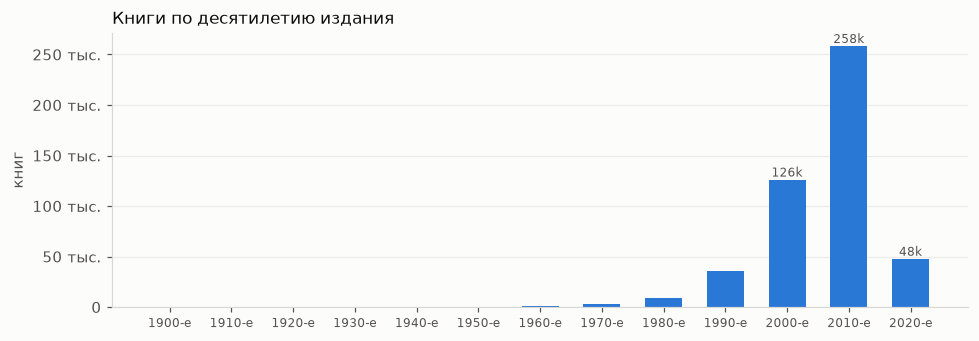

details,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
книг,78,7,30,60,151,426,1058,2986,9456,35843,126261,258407,47837
%,0.0%,0.0%,0.0%,0.0%,0.0%,0.1%,0.2%,0.6%,2.0%,7.4%,26.2%,53.5%,9.9%


In [16]:
decade = (year.dropna() // 10 * 10).astype(int)
dist = decade.value_counts().sort_index()
dist = dist[dist.index >= 1900]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(dist.index.astype(str) + "-е", dist.values, color=BLUE, width=0.6)
ax.set_title("Книги по десятилетию издания", loc="left", fontsize=11)
ax.set_ylabel("книг")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f} тыс." if v else "0")
for x, v in zip(range(len(dist)), dist.values):
    if v > dist.max() * 0.15:
        ax.text(x, v, f"{v / 1000:.0f}k", ha="center", va="bottom", fontsize=8, color=MUTED)
plt.xticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame({"книг": dist, "%": (dist / dist.sum()).map("{:.1%}".format)}).T

In [17]:
print("Примеры, где год не извлёкся:")
miss = year.isna()
pd.DataFrame({"subtitle": meta.loc[miss, "subtitle"], "Publisher": details[miss].map(lambda d: d.get("Publisher")),
              "title": meta.loc[miss, "title"]}).sample(8, random_state=0)

Примеры, где год не извлёкся:


,subtitle,Publisher,title
442101,Kindle Edition,None,"Reading behind Bars: A True Story of Literature, Law, and Life as a Prison Librarian"
409316,None,None,Twelve Months of Monastery Salads: 200 Divine Recipes for All Seasons
441160,None,None,Lift-the-Flap Tab: Hide and Seek Bunnies (Lift-the-Flap Tab Books)
302572,Kindle Edition,None,Forged in Death (The Death Wizard Chronicles Book 1)
89671,None,None,"The Match: Wilde, Book 2"
346422,Kindle Edition,None,His Secret Dragon : Dragon Blood Book 4 (A Dragon Shifter Romance)
418761,None,None,The Weaver Takes a Wife
224965,None,None,The Last Best Hope: Star Trek: Picard


## 5. Описания

In [18]:
desc_text = meta["description"].map(lambda x: " ".join(x).strip())
feat_text = meta["features"].map(lambda x: " ".join(x).strip())
desc_empty, feat_empty = desc_text.eq(""), feat_text.eq("")

print(f"description пустой:                         {pct(desc_empty.sum(), N_BOOKS)}")
print(f"  …но в features есть текст:                 {pct((desc_empty & ~feat_empty).sum(), N_BOOKS)}")
print(f"  …и в features длинный текст (> 200 симв.): {pct((desc_empty & (feat_text.str.len() > 200)).sum(), N_BOOKS)}")
print(f"Совсем без текста (нет ни description, ни features): {pct((desc_empty & feat_empty).sum(), N_BOOKS)}, "
      f"оценок: {pct(ratings_of(desc_empty & feat_empty), N_RATINGS)}")
print()
lens = (desc_text + " " + feat_text).str.len()
print("Длина всего текста (description + features), символов:")
print(lens[lens > 0].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

description пустой:                         132,734 (26.8%)
  …но в features есть текст:                 123,451 (24.9%)
  …и в features длинный текст (> 200 симв.): 107,783 (21.8%)


Совсем без текста (нет ни description, ни features): 9,283 (1.9%), оценок: 95,770 (1.0%)



Длина всего текста (description + features), символов:
count     495063.0
mean        4695.0
std         8294.0
min            1.0
10%          459.0
25%         1030.0
50%         2083.0
75%         4519.0
90%        12893.0
max      1472675.0


**Где на самом деле аннотация.** Похоже, что в Amazon Reviews 2023 для книг `features` — это текст «о книге» со страницы товара,
а `description` — блок Editorial Reviews: рецензии, «About the Author», отрывки. Проверяем.

In [19]:
HDR = {"Review", "About the Author", "Read more", "From the Back Cover", "From the Inside Flap"}
desc_plain = meta["description"].map(
    lambda l: len(l) > 0 and not any(x.strip() in HDR or x.strip().startswith("From ") for x in l))
print(f"features непустой:     {pct((~feat_empty).sum(), N_BOOKS)}")
print(f"description непустой:  {pct((~desc_empty).sum(), N_BOOKS)}")
print(f"description без заголовков рецензий (похож на аннотацию): {pct(desc_plain.sum(), N_BOOKS)}")

features непустой:     485,292 (98.0%)
description непустой:  362,329 (73.2%)
description без заголовков рецензий (похож на аннотацию): 2,661 (0.5%)


In [20]:
print("Примеры: description пустой, аннотация в features")
for t, f in meta.loc[desc_empty & (feat_text.str.len() > 200), ["title", "features"]].sample(4, random_state=0).values:
    print(f"\n• {t}\n  features: {' | '.join(f)[:400]}")

Примеры: description пустой, аннотация в features



• Weirdlings and Wildlings: A Fantasy Coloring Book
  features: Travel back into the unique fantasy world of the weirdlings and wildlings. It's a world filled with a variety of fairies, elves, and other curious creatures all illustrated by watercolorist, Shelah Dow. These odd beings are all splendidly detailed with one thing in common; they’re all whimsical and fun. You’ll find fairies that rest among flowers with dragonflies; a dragon queen with her fanciful 

• One Look: A Sullivan Family Special Edition
  features: I’m a full time single dad. A former NFL player turned coach, tasked with turning around a college team full of kids who either don’t take it seriously or are determined to get injured. | I will absolutely not be falling for my new neighbor. | Lark Butler is pure chaos wrapped in gorgeous, infuriating sunshine. | She showed up out of nowhere––getting paid to cry at a funeral, no less. Who does tha

• Stalk Me Gently: Daddy's Obsession Book 1 of 2
  features: It’s him. Th

In [21]:
# «Мусор» в description: короткие элементы списка — это заголовки разделов страницы Amazon
short = Counter(x.strip() for lst in meta["description"] for x in lst if 0 < len(x.strip()) <= 40)
print("Самые частые короткие элементы description (заголовки разделов):")
pd.DataFrame(short.most_common(25), columns=["элемент", "книг"])

Самые частые короткие элементы description (заголовки разделов):


,элемент,книг
0,About the Author,332597
1,Review,217426
2,",",148219
3,Read more,132113
4,and,117747
5,New York Times,85830
6,Booklist,72133
7,—,69635
8,edition.,56182
9,From the Back Cover,55356


In [22]:
HEADERS = {
    "Review": r"^Review$",
    "About the Author": r"^About the Author$",
    "From the Publisher": r"^From the Publisher$",
    "From the Back Cover": r"^From the Back Cover$",
    "Excerpt / Read more": r"^(Excerpt\. © Reprinted by permission\. All rights reserved\.|Read more)$",
}
for name, pat in HEADERS.items():
    has = meta["description"].map(lambda lst: any(re.match(pat, x.strip()) for x in lst))
    print(f"{name:22} {pct(has.sum(), N_BOOKS)}")

starts_review = meta["description"].map(lambda lst: len(lst) > 0 and lst[0].strip() == "Review")
print(f"\ndescription начинается с «Review» (аннотации может не быть вовсе): {pct(starts_review.sum(), N_BOOKS)}")

Review                 208,701 (42.2%)


About the Author       332,397 (67.1%)


From the Publisher     9,213 (1.9%)


From the Back Cover    55,350 (11.2%)


Excerpt / Read more    141,606 (28.6%)

description начинается с «Review» (аннотации может не быть вовсе): 161,668 (32.7%)


In [23]:
print("Примеры description с рецензиями и «About the Author»:")
mask = meta["description"].map(lambda lst: "Review" in lst and "About the Author" in lst)
for t, d in meta.loc[mask, ["title", "description"]].sample(3, random_state=1).values:
    print(f"\n• {t}")
    for part in d[:8]:
        print(f"    [{part[:150]}{'…' if len(part) > 150 else ''}]")

Примеры description с рецензиями и «About the Author»:



• Pop-up New York
    [From School Library Journal]
    [Gr 2–5—Four spreads of fabulous paper engineering feature two-sided pop-up images of skyscrapers, bridges, museums, and a sports complex, while illust…]
    [Review]
    [A nicely drawn touristy trip through the city... The old architectural standbys — the Empire State Building, the Flatiron Building — are looking great…]
    [About the Author]
    [Jennie Maizels]
    [is the author-illustrator of numerous books for children, including]
    [Pop-up London]

• Tom Slick: True Life Encounters in Cryptozoology
    [Review]
    [""Coleman did an excellent job on this book! Very well written and informative."" --""The Lebanon Daily Record""]
    [About the Author]
    [Loren Coleman is the world's leading cryptozoologist and has done fieldwork, research, and writing about undiscovered animals for the last 41 years. H…]

• The Breaking Point: A Body Farm Novel
    [Review]
    [“Another strong performance in what has become an outsta

## 6. Подозрительные пользователи

«Оценок в день» — по календарному дню UTC (timestamp в миллисекундах).

In [24]:
ratings["day"] = (ratings["timestamp"] // 86_400_000).astype("int32")
per_day = ratings.groupby(["user_id", "day"], observed=True).size()
user_max = per_day.groupby(level=0).max()
user_n = ratings.groupby("user_id").size()

print("Оценок за день на пользователя (по всем парам пользователь–день):")
print(per_day.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
print()
print("Максимум оценок за один день у пользователя:")
for thr in [5, 10, 20, 50, 100]:
    n = (user_max >= thr).sum()
    print(f"  ≥ {thr:>3} в день: {n:>7,} пользователей ({n / len(user_max):.2%}), "
          f"их оценок: {user_n[user_max >= thr].sum():,} ({user_n[user_max >= thr].sum() / N_RATINGS:.1%})")

Оценок за день на пользователя (по всем парам пользователь–день):
count    6931555.0
mean           1.4
std            1.4
min            1.0
50%            1.0
90%            2.0
99%            7.0
99.9%         18.0
max          240.0

Максимум оценок за один день у пользователя:


  ≥   5 в день: 136,529 пользователей (17.59%), их оценок: 2,705,286 (28.5%)
  ≥  10 в день:  27,310 пользователей (3.52%), их оценок: 973,542 (10.3%)
  ≥  20 в день:   5,143 пользователей (0.66%), их оценок: 321,756 (3.4%)


  ≥  50 в день:     280 пользователей (0.04%), их оценок: 36,647 (0.4%)
  ≥ 100 в день:      19 пользователей (0.00%), их оценок: 4,832 (0.1%)


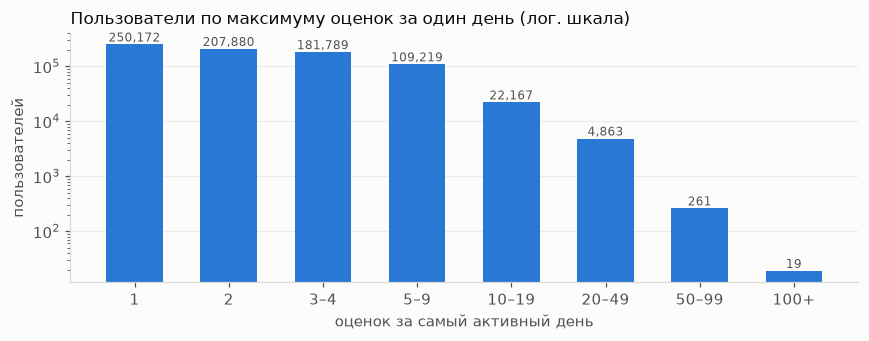

In [25]:
bins = [1, 2, 3, 5, 10, 20, 50, 100, 10_000]
labels = ["1", "2", "3–4", "5–9", "10–19", "20–49", "50–99", "100+"]
hist = pd.cut(user_max, bins=bins, right=False, labels=labels).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(labels, hist.values, color=BLUE, width=0.6)
ax.set_yscale("log")
ax.set_title("Пользователи по максимуму оценок за один день (лог. шкала)", loc="left", fontsize=11)
ax.set_xlabel("оценок за самый активный день")
ax.set_ylabel("пользователей")
for x, v in enumerate(hist.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=MUTED)
plt.tight_layout()
plt.show()

In [26]:
# Топ-20 по максимуму оценок за день
top_days = per_day.sort_values(ascending=False)
top_users = top_days.groupby(level=0).head(1).head(20)
rows = []
for (u, d), n in top_users.items():
    ur = ratings[ratings["user_id"] == u]
    day_r = ur[ur["day"] == d]["rating"]
    rows.append({
        "user_id": u, "оценок за день": n, "дата": pd.to_datetime(d, unit="D").date(),
        "всего оценок": len(ur), "доля в этот день": f"{n / len(ur):.0%}",
        "оценки за день (5/4/3/2/1)": "/".join(str((day_r == k).sum()) for k in [5, 4, 3, 2, 1]),
        "средняя": round(ur["rating"].mean(), 2),
    })
pd.DataFrame(rows)

,user_id,оценок за день,дата,всего оценок,доля в этот день,оценки за день (5/4/3/2/1),средняя
0,AE5SK7TOFENFDV2TWOM2UIRZDB6Q,240,2016-05-18,333,72%,67/101/47/15/10,3.86
1,AHMIFJZEHOTAJPMH42C5KLOE2TJQ,218,2016-11-08,227,96%,92/112/14/0/0,4.32
2,AGC345DNZWNBM5KQY6LNCS66BMXA,175,2013-11-01,326,54%,23/78/58/14/2,3.63
3,AG2GVOFM2ESHP5Y6ASGI3J3RJAJQ,151,2015-03-09,183,83%,106/15/13/3/14,4.33
4,AGCR55N5L3KBAY73EZKWNT5GBBCA,144,2014-12-04,402,36%,90/50/4/0/0,4.52
5,AHXE6B4H22AZB6DQ2AOV4LICXBTQ,143,2015-03-20,330,43%,22/56/61/4/0,3.89
6,AHGMM77R7NADVGMWMHLLL7C3FNPA,142,2019-01-07,306,46%,21/77/29/12/3,3.67
7,AHEV6UAX555JYLFSFEN3L7J7ZQLQ,130,2014-11-17,159,82%,130/0/0/0/0,4.97
8,AHM7BCRFFOEMTWG2T6MFEP3CHJQQ,128,2011-05-30,678,19%,14/47/39/18/10,3.71
9,AETZECHENB6OEZ6B46IGDBBGTF4A,122,2007-04-10,387,32%,122/0/0/0/0,5.00


In [27]:
nuniq = ratings.groupby("user_id")["rating"].nunique()
same = nuniq == 1
print(f"Пользователей, у которых все оценки одинаковые: {pct(same.sum(), len(nuniq))}, "
      f"их оценок: {pct(user_n[same].sum(), N_RATINGS)}")
print()
buckets = pd.cut(user_n, [5, 10, 20, 50, 100, 100_000], right=False, labels=["5–9", "10–19", "20–49", "50–99", "100+"])
tab = pd.DataFrame({"пользователей": buckets.value_counts(), "все оценки одинаковые": buckets[same].value_counts()})
tab["доля"] = (tab["все оценки одинаковые"] / tab["пользователей"]).map("{:.1%}".format)
print("По числу оценок у пользователя:")
print(tab.sort_index().to_string())
print()
print("Какая это одинаковая оценка:")
first = ratings.groupby("user_id")["rating"].first()
print(first[same].value_counts().sort_index().to_string())

Пользователей, у которых все оценки одинаковые: 197,887 (25.5%), их оценок: 1,622,685 (17.1%)

По числу оценок у пользователя:
       пользователей  все оценки одинаковые   доля
5–9           518309                 158515  30.6%
10–19         174447                  31775  18.2%
20–49          64747                   6843  10.6%
50–99          12759                    650   5.1%
100+            6108                    104   1.7%

Какая это одинаковая оценка:


rating
1       262
2        31
3       185
4      2229
5    195180


In [28]:
# Сочетание признаков: много за день И все оценки одинаковые
both = same & (user_max >= 20)
print(f"Все оценки одинаковые И ≥ 20 оценок за один день: {both.sum():,} пользователей, {user_n[both].sum():,} оценок")

Все оценки одинаковые И ≥ 20 оценок за один день: 1,588 пользователей, 60,972 оценок


## 7. Категории

Уровень 1 — корень (`Books`), уровень 2 — раздел, уровень 3 — подраздел.

In [29]:
depth = cats.map(len)
print("Длина пути категорий (включая корень):")
print(pd.DataFrame({"книг": depth.value_counts().sort_index(),
                    "%": (depth.value_counts().sort_index() / N_BOOKS).map("{:.2%}".format)}).T.to_string())
print()
print("Корни:")
print(meta["root"].fillna("— нет категорий —").value_counts().to_string())
print()
print("Примеры путей глубже 3 уровней:")
for c in cats[depth >= 5].sample(6, random_state=0):
    print("  " + " > ".join(c))

Длина пути категорий (включая корень):


categories      0      2       3      4      5      6
книг         9043   7061  474865   2643   1359     92
%           1.83%  1.43%  95.92%  0.53%  0.27%  0.02%

Корни:
root
Books                        485595
— нет категорий —              9043
Audible Books & Originals       425

Примеры путей глубже 3 уровней:
  Books > Literature & Fiction > Genre Fiction > Horror > Dark Fantasy
  Books > Teen & Young Adult > Science Fiction & Fantasy > Fantasy > Fairy Tales & Folklore > Adaptations
  Books > Teen & Young Adult > Science Fiction & Fantasy > Horror > Ghosts
  Books > Literature & Fiction > United States > Black & African American > Romance
  Audible Books & Originals > Science Fiction & Fantasy > Fantasy > Paranormal & Urban > Contemporary
  Books > Literature & Fiction > Genre Fiction > Historical > Cultural Heritage


In [30]:
books_root = meta["root"].eq("Books")
l2 = meta.loc[books_root, "cat2"].value_counts()
l2_df = pd.DataFrame({"книг": l2, "%": (l2 / books_root.sum()).map("{:.2%}".format)})
print(f"Разделов (уровень 2): {len(l2)}, из них < 100 книг: {(l2 < 100).sum()} (в них {l2[l2 < 100].sum():,} книг)")
print("\nПримеры разделов < 100 книг — в основном промо-подборки Amazon:")
print(", ".join(f"{c} ({n})" for c, n in l2[l2 < 100].head(25).items()))
l2_df.head(35)

Разделов (уровень 2): 148, из них < 100 книг: 107 (в них 614 книг)

Примеры разделов < 100 книг — в основном промо-подборки Amazon:
Sponsored Selections (45), Dear Santa Children's Books (38), Sheet Music & Scores (37), Books Markdowns (28), Specialty Stores (23), Blowout Books (21), MOD CreateSpace Books (19), Books in Bulk (19), Holiday Books Offer (18), Best Books of 2016 (16), Back to School for Teachers (14), Get a free digital comic with purchase (13), McGraw-Hill Engineering Store (13), Holiday Books (13), Libros en español (12), Books Santa 2012 (12), Money & Markets (12), Seasonal Children's Books (11), New Year, New You 2015 (10), Political Parties (10), Amazon Publishing (10), Moleskine (9), Books Outlet (9), Harlequin Store (8), Special Offer (8)


,книг,%
cat2,,
Literature & Fiction,99623,20.52%
Children's Books,57551,11.85%
"Mystery, Thriller & Suspense",56722,11.68%
"Crafts, Hobbies & Home",24026,4.95%
Arts & Photography,22124,4.56%
Christian Books & Bibles,19422,4.00%
Teen & Young Adult,19163,3.95%
Biographies & Memoirs,19161,3.95%
History,17872,3.68%


In [31]:
l3 = meta.loc[books_root & meta["cat3"].notna()].groupby(["cat2", "cat3"]).size().sort_values(ascending=False)
print(f"Подразделов (уровень 3): {len(l3)}")
print(f"  < 100 книг: {(l3 < 100).sum()} (в них {l3[l3 < 100].sum():,} книг)")
print(f"  < 20 книг:  {(l3 < 20).sum()}")
print(f"Медиана книг в подразделе: {int(l3.median())}")
print()
print("Подразделов на раздел (топ-10 разделов):")
print(l3.groupby(level=0).size().loc[l2.index[:10]].to_string())

Подразделов (уровень 3): 581
  < 100 книг: 341 (в них 6,216 книг)
  < 20 книг:  233
Медиана книг в подразделе: 41

Подразделов на раздел (топ-10 разделов):
cat2
Literature & Fiction            18
Children's Books                24
Mystery, Thriller & Suspense     2
Crafts, Hobbies & Home           8
Arts & Photography              17
Christian Books & Bibles        15
Teen & Young Adult              13
Biographies & Memoirs           11
History                         12
Cookbooks, Food & Wine          17


In [32]:
print("Крупнейшие подразделы:")
print(l3.head(15).to_string())
print("\nПримеры маленьких подразделов (< 100 книг):")
print(l3[l3 < 100].sample(12, random_state=0).to_string())

Крупнейшие подразделы:
cat2                          cat3                      
Literature & Fiction          Genre Fiction                 60012
Mystery, Thriller & Suspense  Thrillers & Suspense          38512
Children's Books              Growing Up & Facts of Life    18983
Mystery, Thriller & Suspense  Mystery                       18192
Crafts, Hobbies & Home        Crafts & Hobbies              13418
Teen & Young Adult            Literature & Fiction          12223
History                       Americas                       9378
Children's Books              Literature & Fiction           8880
Comics & Graphic Novels       Graphic Novels                 7916
Literature & Fiction          United States                  7603
                              Action & Adventure             7482
Christian Books & Bibles      Christian Living               7214
Arts & Photography            Music                          7074
Politics & Social Sciences    Politics & Government          6

In [33]:
SERVICE = ["New, Used & Rental Textbooks", "ASINs for HQP", "Textbook Rental ASINs", "Deals in Books",
           "Large Print", "Boxed Sets", "Books on CD", "Calendars"]
print("Служебные / нетематические разделы (уровень 2):")
for s in SERVICE:
    n = int(l2.get(s, 0))
    print(f"  {s:32} {n:>6,}")
print("\nЧто внутри «New, Used & Rental Textbooks» (уровень 3):")
print(l3.loc["New, Used & Rental Textbooks"].head(10).to_string() if "New, Used & Rental Textbooks" in l3.index.get_level_values(0) else "—")

Служебные / нетематические разделы (уровень 2):
  New, Used & Rental Textbooks      7,021
  ASINs for HQP                       281
  Textbook Rental ASINs               180
  Deals in Books                      135
  Large Print                         181
  Boxed Sets                          682
  Books on CD                         148
  Calendars                           473

Что внутри «New, Used & Rental Textbooks» (уровень 3):
cat3
Medicine & Health Sciences    2626
Humanities                    2355
Social Sciences                763
Science & Mathematics          478
Business & Finance             339
Education                      197
Computer Science                89
Test Prep & Study Guides        28
Law                             23
Reference                       22


## Сводка

Правила и пороги **не применены** — это предложения для обсуждения. Цифры считаются из ячеек выше.

In [34]:
from IPython.display import Markdown

reliable_nonbook = (RULES["категория: Calendars"] | RULES["категория: Stationery"]
                    | RULES["формат: Calendar/Cards/Map/Diary"] | RULES["название: calendar + год/wall/desk"])
coloring = RULES["название: coloring book"]
audible = RULES["категория: Audible"]
susp = same & (user_max >= 20)
deep = depth >= 4
small_l2 = meta["cat2"].isin(l2[l2 < 100].index)
service_l2 = meta["cat2"].isin(["New, Used & Rental Textbooks", "ASINs for HQP", "Textbook Rental ASINs", "Deals in Books"])

def b(mask):
    return f"{mask.sum():,} книг ({mask.mean():.1%}), {ratings_of(mask) / N_RATINGS:.1%} оценок"

rows = [
    ("Дубли изданий (строгий ключ)",
     f"{n_groups:,} групп, {len(dup_idx):,} книг ({len(dup_idx) / N_BOOKS:.1%}); «лишних» карточек {extra:,} ({extra / N_BOOKS:.1%}); "
     f"на книгах групп {ratings_of(dup_mask) / N_RATINGS:.1%} оценок",
     "Склеивать по строгому ключу (название без скобок и пометок изданий + автор). Это действительно издания одной книги "
     "(Hardcover + Paperback + Kindle…). Номер тома извлекать **до** удаления скобок и добавлять в ключ. "
     "Главная карточка группы — издание с наибольшим числом оценок."),
    ("Дубли по мягкому ключу (часть до «:»)",
     f"ещё {len(diff_sub):,} групп «то же до двоеточия, другое после»",
     "**Не использовать** — склеивает разные книги (Henri Cartier-Bresson: The Decisive Moment / Photographer / …)."),
    ("Разные номера томов в группе",
     f"{len(vol_keys):,} групп ({meta['key_strict'].isin(vol_keys).sum():,} книг)",
     "Не склеивать (Loving Angelica Book 1/2/3/5, Gulag Archipelago Vol. 2/3). Частично это ошибки нумерации Amazon (Alter Ego Book 9/10) — их немного, можно пренебречь."),
    ("Пользователь оценил 2+ издания одной книги",
     f"{(multi > 1).sum():,} пар, {multi[multi > 1].sum() / N_RATINGS:.2%} оценок",
     "Как в 1.3: после склейки оставить последнюю оценку."),
    ("Нет автора",
     f"{(~has_author).sum():,} книг ({(~has_author).mean():.1%})",
     "В склейке не участвуют. Проверить, можно ли взять автора из `store` («Name (Author)»)."),
    ("Не книги — надёжные признаки",
     b(reliable_nonbook),
     "Удалять: категории Calendars и Stationery, формат Calendar/Cards/Map/Diary/Poster, «calendar» + год / wall / desk в названии."),
    ("Раскраски (coloring book)",
     b(coloring),
     "**Решить:** формально книги, но не для чтения. Предлагаю удалить: они засоряют рекомендации и онбординг."),
    ("Слова journal / diary / notebook / planner / agenda",
     f"{(RULES['название: notebook / journal'] | RULES['название: diary'] | RULES['название: planner / organizer']).sum():,} книг",
     "**Не использовать как правило** — много ложных: Diary of a Wimpy Kid, Agenda 21, The Venice Sketchbook, Gravity Falls: Journal 3. "
     "Настоящие блокноты и так ловятся категорией Stationery и форматом Diary."),
    ("Summary of… / Workbook for… / Study Guide",
     f"{RULES['название: summary of'].sum():,} / {RULES['название: workbook for'].sum():,} / {RULES['название: study guide'].sum():,} книг",
     "Summary — пренебрежимо мало, удалить. Workbook и Study Guide — учебные пособия и подготовка к тестам: оставить (это книги) или убрать вместе с разделом Test Preparation — решить."),
    ("Корень «Audible Books & Originals»",
     b(audible) + "; автор пуст у всех",
     "Удалить: аудиоверсии, у которых нет автора, а книги в основном дублируют печатные."),
    ("Неанглоязычные",
     b(non_en) + f"; язык не указан у {lang.isna().mean():.1%}",
     "Удалить книги без English в Language. Книги без языка оставить (почти все на английском)."),
    ("Год издания",
     f"извлекается у {year.notna().mean():.1%}; вне 1900–2023 — {odd.sum():,}",
     "Порядок: Publication date → Publisher (дата в скобках) → subtitle. Годы вне 1900–2023 — пусто."),
    ("Аннотация лежит в features, а не в description",
     f"features непустой у {(~feat_empty).mean():.1%}; description похож на аннотацию только у {desc_plain.mean():.1%}",
     "**Поправить 1.3.3:** основной текст книги — `features`. `description` = рецензии и «About the Author» — "
     "как доп. текст, после вырезания заголовков (Review, About the Author, Read more…)."),
    ("Совсем без текста",
     b(desc_empty & feat_empty),
     "Как в 1.3: эмбеддинг по названию и категориям."),
    ("Много оценок в день",
     f"≥ 20 в день у {(user_max >= 20).sum():,} пользователей; ≥ 50 — у {(user_max >= 50).sum():,}",
     "Само по себе не удалять: импорт старых оценок пачкой — нормальное поведение."),
    ("Все оценки одинаковые",
     f"{same.sum():,} пользователей ({same.mean():.1%}), почти все — одни пятёрки, в основном 5–9 оценок",
     "Само по себе не удалять: так оценивают обычные пользователи с малым числом оценок."),
    ("Все одинаковые И ≥ 20 в один день",
     f"{susp.sum():,} пользователей, {user_n[susp].sum():,} оценок ({user_n[susp].sum() / N_RATINGS:.2%})",
     "Кандидат на удаление (похоже на накрутку). Порог обсудить."),
    ("Категории глубже 2 уровней под Books",
     b(deep),
     "**Поправить 1.1:** у 96% книг ровно 2 уровня под корнем, но у 0,8% — до 5. Для тем используем уровни 2–3, глубже — отбрасываем."),
    ("Мелкие разделы уровня 2 (< 100 книг)",
     f"{(l2 < 100).sum()} из {len(l2)} разделов, {small_l2.sum():,} книг",
     "Это промо-подборки Amazon (Best Books of 2013, Fall into Cooking…). Перенести книги в тематический раздел по уровню 3 или из дубля; иначе — «Другое»."),
    ("Служебные разделы (Textbooks, ASINs for HQP, Deals…)",
     b(service_l2),
     "Textbooks — переназначить по уровню 3 (Medicine, Humanities…), остальные — как мелкие разделы."),
    ("Подразделы уровня 3 (< 100 книг)",
     f"{(l3 < 100).sum()} из {len(l3)}, медиана {int(l3.median())} книг",
     "Для онбординга не нужны напрямую: подтемы строим кластерами (2.3). Уровень 3 — признак для моделей."),
    ("Нет категорий",
     b(meta["root"].isna()),
     "Взять из дубля после склейки; иначе — только кластер по тексту."),
]
table = "| Проблема | Затронуто | Предложение |\n|---|---|---|\n" + "\n".join(f"| {p} | {a} | {s} |" for p, a, s in rows)
Markdown(table)

| Проблема | Затронуто | Предложение |
|---|---|---|
| Дубли изданий (строгий ключ) | 45,650 групп, 104,594 книг (21.1%); «лишних» карточек 58,944 (11.9%); на книгах групп 37.6% оценок | Склеивать по строгому ключу (название без скобок и пометок изданий + автор). Это действительно издания одной книги (Hardcover + Paperback + Kindle…). Номер тома извлекать **до** удаления скобок и добавлять в ключ. Главная карточка группы — издание с наибольшим числом оценок. |
| Дубли по мягкому ключу (часть до «:») | ещё 15,137 групп «то же до двоеточия, другое после» | **Не использовать** — склеивает разные книги (Henri Cartier-Bresson: The Decisive Moment / Photographer / …). |
| Разные номера томов в группе | 59 групп (157 книг) | Не склеивать (Loving Angelica Book 1/2/3/5, Gulag Archipelago Vol. 2/3). Частично это ошибки нумерации Amazon (Alter Ego Book 9/10) — их немного, можно пренебречь. |
| Пользователь оценил 2+ издания одной книги | 3,729 пар, 0.08% оценок | Как в 1.3: после склейки оставить последнюю оценку. |
| Нет автора | 59,614 книг (12.0%) | В склейке не участвуют. Проверить, можно ли взять автора из `store` («Name (Author)»). |
| Не книги — надёжные признаки | 5,442 книг (1.1%), 0.9% оценок | Удалять: категории Calendars и Stationery, формат Calendar/Cards/Map/Diary/Poster, «calendar» + год / wall / desk в названии. |
| Раскраски (coloring book) | 5,592 книг (1.1%), 1.3% оценок | **Решить:** формально книги, но не для чтения. Предлагаю удалить: они засоряют рекомендации и онбординг. |
| Слова journal / diary / notebook / planner / agenda | 3,303 книг | **Не использовать как правило** — много ложных: Diary of a Wimpy Kid, Agenda 21, The Venice Sketchbook, Gravity Falls: Journal 3. Настоящие блокноты и так ловятся категорией Stationery и форматом Diary. |
| Summary of… / Workbook for… / Study Guide | 22 / 421 / 822 книг | Summary — пренебрежимо мало, удалить. Workbook и Study Guide — учебные пособия и подготовка к тестам: оставить (это книги) или убрать вместе с разделом Test Preparation — решить. |
| Корень «Audible Books & Originals» | 425 книг (0.1%), 0.0% оценок; автор пуст у всех | Удалить: аудиоверсии, у которых нет автора, а книги в основном дублируют печатные. |
| Неанглоязычные | 1,095 книг (0.2%), 0.1% оценок; язык не указан у 4.5% | Удалить книги без English в Language. Книги без языка оставить (почти все на английском). |
| Год издания | извлекается у 97.6%; вне 1900–2023 — 408 | Порядок: Publication date → Publisher (дата в скобках) → subtitle. Годы вне 1900–2023 — пусто. |
| Аннотация лежит в features, а не в description | features непустой у 98.0%; description похож на аннотацию только у 0.5% | **Поправить 1.3.3:** основной текст книги — `features`. `description` = рецензии и «About the Author» — как доп. текст, после вырезания заголовков (Review, About the Author, Read more…). |
| Совсем без текста | 9,283 книг (1.9%), 1.0% оценок | Как в 1.3: эмбеддинг по названию и категориям. |
| Много оценок в день | ≥ 20 в день у 5,143 пользователей; ≥ 50 — у 280 | Само по себе не удалять: импорт старых оценок пачкой — нормальное поведение. |
| Все оценки одинаковые | 197,887 пользователей (25.5%), почти все — одни пятёрки, в основном 5–9 оценок | Само по себе не удалять: так оценивают обычные пользователи с малым числом оценок. |
| Все одинаковые И ≥ 20 в один день | 1,588 пользователей, 60,972 оценок (0.64%) | Кандидат на удаление (похоже на накрутку). Порог обсудить. |
| Категории глубже 2 уровней под Books | 4,094 книг (0.8%), 0.5% оценок | **Поправить 1.1:** у 96% книг ровно 2 уровня под корнем, но у 0,8% — до 5. Для тем используем уровни 2–3, глубже — отбрасываем. |
| Мелкие разделы уровня 2 (< 100 книг) | 107 из 148 разделов, 614 книг | Это промо-подборки Amazon (Best Books of 2013, Fall into Cooking…). Перенести книги в тематический раздел по уровню 3 или из дубля; иначе — «Другое». |
| Служебные разделы (Textbooks, ASINs for HQP, Deals…) | 7,617 книг (1.5%), 0.9% оценок | Textbooks — переназначить по уровню 3 (Medicine, Humanities…), остальные — как мелкие разделы. |
| Подразделы уровня 3 (< 100 книг) | 341 из 581, медиана 41 книг | Для онбординга не нужны напрямую: подтемы строим кластерами (2.3). Уровень 3 — признак для моделей. |
| Нет категорий | 9,043 книг (1.8%), 0.9% оценок | Взять из дубля после склейки; иначе — только кластер по тексту. |